# Prediksjon av liggetid ved akuttinnleggelse – Random Forest

## Formål

Formålet med analysen er å undersøke om lengden på sykehusopphold ved akuttinnleggelse kan predikeres ved hjelp av seks laboratorieprøver tatt nær innleggelsestidspunktet, samt pasientens alder.

Analysen er gjennomført som del av studentprosjektet i emnet IT6117 – Health Data Analyses with AI ved NTNU.

## Datagrunnlag

Dataene er hentet fra MIMIC-IV (versjon 3.1), modulen `hosp`, og bearbeidet i Google BigQuery.

Det endelige analysedatasettet omfatter 56 917 akuttinnleggelser med komplette verdier for seks laboratorieprøver: kreatinin, glukose, hemoglobin, kalium, natrium og leukocytter.

Laboratorieprøvene er valgt innenfor et tidsvindu på seks timer før til seks timer etter innleggelse.

## Metode

Random Forest-regresjon benyttes som hovedmetode for å predikere liggetid (LOS) i dager. Analysen gjennomføres i Python ved hjelp av Google Colab og scikit-learn.

Modellens prediksjonsevne evalueres ved hjelp av Mean Absolute Error (MAE) og sammenlignes med en enkel referansemodell basert på median liggetid.


## 1. Tilkobling og innlasting av analysedata

Kjør cellene nedenfor i Colab for å autentisere deg og hente analysedatasettet fra BigQuery.


In [2]:
from google.colab import auth
auth.authenticate_user()

In [3]:

from google.cloud import bigquery

client = bigquery.Client(project="arnhildmimic")

query = """
SELECT *
FROM `arnhildmimic.mimic_analyse.analyse_data`
"""

df = client.query(query).to_dataframe()

print("Antall rader og kolonner:", df.shape)
df.head()


Antall rader og kolonner: (56917, 10)


,subject_id,hadm_id,alder,kreatinin,glukose,hemoglobin,kalium,natrium,leukocytter,los
0,10296472,20967375,43,6.5,95.0,8.7,1.5,130.0,7.0,7.786111
1,12224263,23294937,52,0.1,75.0,6.6,1.7,148.0,5.3,1.865278
2,16573207,21399919,42,0.5,919.0,7.4,1.8,176.0,7.6,2.717361
3,10547408,27351978,43,0.4,114.0,9.9,1.8,121.0,13.6,15.970833
4,16878717,20838215,78,0.2,100.0,11.0,1.8,147.0,5.7,5.694444


## 2. Variabler og første oppdeling i trenings- og testdata

De syv prediktorene er alder og seks laboratorieprøver. `GroupShuffleSplit` deler etter `subject_id` for å holde innleggelser fra samme pasient atskilt.


In [4]:

from sklearn.model_selection import GroupShuffleSplit

variabler = [
    "alder", "kreatinin", "glukose",
    "hemoglobin", "kalium", "natrium",
    "leukocytter"
]

X = df[variabler].astype(float)
y = df["los"].astype(float)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=df["subject_id"])
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Treningsdata:", len(X_train))
print("Testdata:", len(X_test))
print("Antall variabler:", X_train.shape[1])


Treningsdata: 45554
Testdata: 11363
Antall variabler: 7


## 3. Innledende Random Forest-modell

Den første modellen trenes på treningsutvalget og vurderes på testutvalget. Dette er en del av den innledende utforskningen.


In [5]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Opprett Random Forest-modellen
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Tren modellen
rf.fit(X_train, y_train)

# Prediker liggetid for testdataene
y_pred = rf.predict(X_test)

# Beregn gjennomsnittlig prediksjonsfeil
mae = mean_absolute_error(y_test, y_pred)

print("Random Forest er ferdig trent!")
print("MAE:", round(mae, 2), "dager")


Random Forest er ferdig trent!
MAE: 5.49 dager


## 4. Første sammenligning med referansemodell

Referansemodellen predikerer median liggetid fra treningsutvalget for alle innleggelser. Begge modeller vurderes med MAE på samme testutvalg.


In [6]:

import numpy as np
from sklearn.metrics import mean_absolute_error

# Referansemodell: Prediker median liggetid
median_los = y_train.median()

# Samme prediksjon for alle i testdatasettet
baseline_pred = np.full(len(y_test), median_los)

# Beregn prediksjonsfeil
baseline_mae = mean_absolute_error(
    y_test, baseline_pred
)

print("Median liggetid i treningsdata:",
      round(median_los, 2), "dager")

print("MAE referansemodell:",
      round(baseline_mae, 2), "dager")

print("MAE Random Forest:",
      round(mae, 2), "dager")


Median liggetid i treningsdata: 4.61 dager
MAE referansemodell: 4.74 dager
MAE Random Forest: 5.49 dager


In [7]:
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Beregn R² og RMSE for Random Forest
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("R² Random Forest:", round(r2, 3))
print("RMSE Random Forest:", round(rmse, 2), "dager")

R² Random Forest: -0.013
RMSE Random Forest: 9.63 dager


## 5. Undersøkelse av overtilpasning og enklere modell

Vi sammenligner feil på trenings- og testdata og prøver en modell med begrenset kompleksitet.


In [8]:

# Prediksjoner på treningsdataene
y_pred_train = rf.predict(X_train)

# Beregn treningsfeil
mae_train = mean_absolute_error(
    y_train, y_pred_train
)

print("MAE treningsdata:",
      round(mae_train, 2), "dager")

print("MAE testdata:",
      round(mae, 2), "dager")


MAE treningsdata: 2.0 dager
MAE testdata: 5.49 dager


In [9]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Random Forest med begrenset kompleksitet
rf_enkel = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

# Tren modellen
rf_enkel.fit(X_train, y_train)

# Prediksjoner
pred_train = rf_enkel.predict(X_train)
pred_test = rf_enkel.predict(X_test)

# Beregn feil
mae_train_enkel = mean_absolute_error(
    y_train, pred_train
)
mae_test_enkel = mean_absolute_error(
    y_test, pred_test
)

print("MAE treningsdata:",
      round(mae_train_enkel, 2), "dager")
print("MAE testdata:",
      round(mae_test_enkel, 2), "dager")


MAE treningsdata: 4.94 dager
MAE testdata: 5.12 dager


In [10]:
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

r2_enkel = r2_score(y_test, pred_test)
rmse_enkel = np.sqrt(mean_squared_error(y_test, pred_test))

print("R²:", round(r2_enkel, 3))
print("RMSE:", round(rmse_enkel, 2), "dager")
print("MAE:", round(mae_test_enkel, 2), "dager")

R²: 0.031
RMSE: 9.42 dager
MAE: 5.12 dager


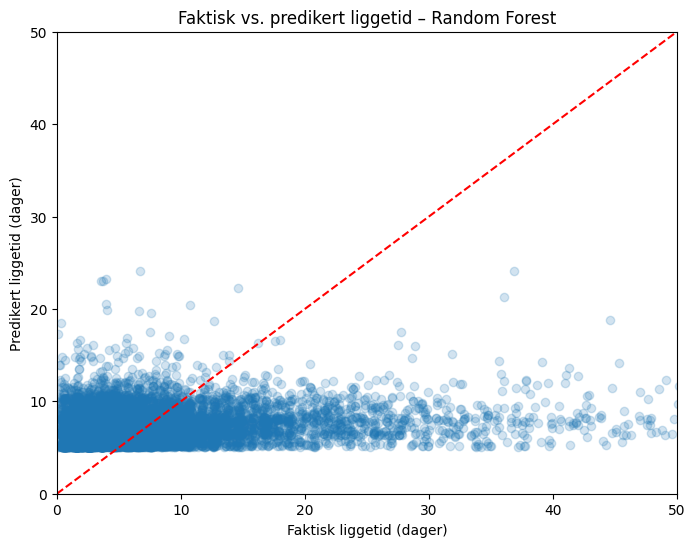

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, pred_test, alpha=0.2)

plt.plot([0, 50], [0, 50], 'r--')

plt.xlim(0, 50)
plt.ylim(0, 50)

plt.xlabel("Faktisk liggetid (dager)")
plt.ylabel("Predikert liggetid (dager)")
plt.title("Faktisk vs. predikert liggetid – Random Forest")

plt.show()

### Predicted versus Observed Length of Stay

The scatter plot compares predicted and observed hospital length of stay for the Random Forest model with a maximum tree depth of 5.

The model tended to overestimate shorter hospital stays and underestimate longer stays. Predicted values were concentrated within a relatively narrow range, while observed length of stay varied considerably.

These findings indicate that the model had limited ability to predict the full variation in hospital length of stay.

## 6. Eget valideringsutvalg

Den opprinnelige treningsdelen deles videre i nytt treningsutvalg og valideringsutvalg, fortsatt gruppert etter pasient. De registrerte størrelsene var 36 493 trening, 9 061 validering og 11 363 test.

**Metodisk begrensning:** Testutvalget ble allerede brukt under innledende modellutvikling. Det er derfor ikke et helt uberørt slutt-testutvalg, og resultater fra dette må tolkes med forsiktighet.


In [12]:

from sklearn.model_selection import GroupShuffleSplit

# Del de opprinnelige treningsdataene
splitter_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

# Pasient-ID for treningsdataene
pasienter_train = df.iloc[train_idx]["subject_id"]

idx_train, idx_val = next(
    splitter_val.split(
        X_train,
        y_train,
        groups=pasienter_train
    )
)

# Nye trenings- og valideringsutvalg
X_train_ny = X_train.iloc[idx_train]
X_val = X_train.iloc[idx_val]

y_train_ny = y_train.iloc[idx_train]
y_val = y_train.iloc[idx_val]

print("Treningsutvalg:", len(X_train_ny))
print("Valideringsutvalg:", len(X_val))
print("Testutvalg:", len(X_test))


Treningsutvalg: 36493
Valideringsutvalg: 9061
Testutvalg: 11363


## 7. Sammenligning av ulike tredybder på valideringsdata

Tre Random Forest-modeller med maksimal dybde 3, 5 og 10 sammenlignes ved MAE på valideringsutvalget.


In [13]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

resultater = []

for dybde in [3, 5, 10]:
    modell = RandomForestRegressor(
        n_estimators=100,
        max_depth=dybde,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=-1
    )

    modell.fit(X_train_ny, y_train_ny)

    prediksjon = modell.predict(X_val)
    feil = mean_absolute_error(y_val, prediksjon)

    resultater.append((dybde, feil))

    print(
        "Maks dybde:", dybde,
        "- MAE:", round(feil, 2), "dager"
    )


Maks dybde: 3 - MAE: 5.07 dager
Maks dybde: 5 - MAE: 5.02 dager
Maks dybde: 10 - MAE: 4.99 dager


## 8. Referansemodell mot beste Random Forest på valideringsdata

Referansemodellen bruker median liggetid fra det **nye treningsutvalget**, og sammenlignes med laveste validerings-MAE blant de tre Random Forest-modellene.

**Registrerte resultater:** Referansemodell 4,63 dager; Random Forest 4,99 dager (maks dybde 10). Lavere MAE er bedre. Referansemodellen gjorde det dermed bedre på dette valideringsutvalget.


In [14]:

import numpy as np
from sklearn.metrics import mean_absolute_error

# Median liggetid i det nye treningsutvalget
median_train = y_train_ny.median()

# Referansemodellen predikerer samme verdi for alle
pred_baseline_val = np.full(len(y_val), median_train)

# Beregn MAE på valideringsutvalget
mae_baseline_val = mean_absolute_error(
    y_val, pred_baseline_val
)

print("Median liggetid:", round(median_train, 2))
print("MAE referansemodell:",
      round(mae_baseline_val, 2), "dager")
print("MAE Random Forest:",
      round(min(feil for dybde, feil in resultater), 2),
      "dager")


Median liggetid: 4.63
MAE referansemodell: 4.63 dager
MAE Random Forest: 4.99 dager


## 9. Variabelbetydning i Random Forest

Modellen med maksimal dybde 10 brukes til å undersøke hvilke variabler som bidrar mest til oppdelingene i trærne. Variabelbetydning er ikke det samme som årsakssammenheng.


In [15]:

import pandas as pd
from sklearn.ensemble import RandomForestRegressor

# Tren modellen med valgt tredybde
rf_valgt = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

rf_valgt.fit(X_train_ny, y_train_ny)

# Hent variablenes betydning
betydning = pd.DataFrame({
    "Variabel": X_train_ny.columns,
    "Betydning": rf_valgt.feature_importances_
})

betydning = betydning.sort_values(
    "Betydning", ascending=False
)

print(betydning)


      Variabel  Betydning
6  leukocytter   0.275647
3   hemoglobin   0.192943
0        alder   0.126034
2      glukose   0.118849
5      natrium   0.097954
1    kreatinin   0.096991
4       kalium   0.091583


In [16]:
# Undersøk fordelingen av liggetid
print("Totalt antall innleggelser:", len(df))

print("Innleggelser med liggetid over 30 dager:",
      (df["los"] > 30).sum())

print("Innleggelser med liggetid på maks 30 dager:",
      (df["los"] <= 30).sum())

print("Andel med liggetid over 30 dager:",
      round((df["los"] > 30).mean() * 100, 2), "%")

Totalt antall innleggelser: 56917
Innleggelser med liggetid over 30 dager: 1426
Innleggelser med liggetid på maks 30 dager: 55491
Andel med liggetid over 30 dager: 2.51 %


In [17]:
# Datasett for sensitivitetsanalyse
df_30 = df[df["los"] <= 30].copy()

print("Antall innleggelser i sensitivitetsanalysen:", len(df_30))
print("Antall unike pasienter:", df_30["subject_id"].nunique())

Antall innleggelser i sensitivitetsanalysen: 55491
Antall unike pasienter: 41535


In [18]:
from sklearn.model_selection import GroupShuffleSplit

# Samme prediktorer som i hovedanalysen
X_30 = df_30[variabler].astype(float)
y_30 = df_30["los"].astype(float)

# Del data på pasientnivå
splitter_30 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx_30, test_idx_30 = next(
    splitter_30.split(
        X_30, y_30,
        groups=df_30["subject_id"]
    )
)

X_train_30 = X_30.iloc[train_idx_30]
X_test_30 = X_30.iloc[test_idx_30]

y_train_30 = y_30.iloc[train_idx_30]
y_test_30 = y_30.iloc[test_idx_30]

print("Treningsdata:", len(X_train_30))
print("Testdata:", len(X_test_30))

Treningsdata: 44390
Testdata: 11101


In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Random Forest for opphold på maks 30 dager
rf_30 = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

# Tren modellen
rf_30.fit(X_train_30, y_train_30)

# Prediker liggetid i testdatasettet
pred_test_30 = rf_30.predict(X_test_30)

# Beregn evalueringsmål
mae_30 = mean_absolute_error(y_test_30, pred_test_30)
rmse_30 = np.sqrt(mean_squared_error(y_test_30, pred_test_30))
r2_30 = r2_score(y_test_30, pred_test_30)

print("MAE:", round(mae_30, 2), "dager")
print("RMSE:", round(rmse_30, 2), "dager")
print("R²:", round(r2_30, 3))

MAE: 3.84 dager
RMSE: 5.34 dager
R²: 0.052


In [20]:
# Referansemodell for sensitivitetsanalysen
median_30 = y_train_30.median()

baseline_pred_30 = np.full(
    len(y_test_30), median_30
)

baseline_mae_30 = mean_absolute_error(
    y_test_30, baseline_pred_30
)

print("Median liggetid:", round(median_30, 2))
print("MAE referansemodell:", round(baseline_mae_30, 2))
print("MAE Random Forest:", round(mae_30, 2))

Median liggetid: 4.54
MAE referansemodell: 3.71
MAE Random Forest: 3.84


### 11. Sensitivity Analysis: Excluding Hospital Stays Over 30 Days

A sensitivity analysis was performed to assess model performance when hospital stays exceeding 30 days were excluded.

Of the original 56,917 admissions, 1,426 (2.51%) had a length of stay exceeding 30 days. The restricted dataset contained 55,491 admissions from 41,535 unique patients.

A Random Forest model was trained using the same hyperparameters as the main analysis, with a new patient-level training and test split.

The model achieved an MAE of 3.84 days, an RMSE of 5.34 days, and an R² of 0.052. The median-based baseline model achieved an MAE of 3.71 days.

Prediction errors were lower than in the main analysis, but Random Forest still did not outperform the baseline model in terms of MAE. The results should be interpreted cautiously because the restricted analysis used a different patient population and test set.

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Opprett og tren lineær regresjonsmodell
lr = LinearRegression()
lr.fit(X_train, y_train)

# Prediksjoner på testdata
pred_lr = lr.predict(X_test)

# Beregn evalueringsmål
mae_lr = mean_absolute_error(y_test, pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, pred_lr))
r2_lr = r2_score(y_test, pred_lr)

print("Lineær regresjon")
print("MAE:", round(mae_lr, 2), "dager")
print("RMSE:", round(rmse_lr, 2), "dager")
print("R²:", round(r2_lr, 3))

Lineær regresjon
MAE: 5.17 dager
RMSE: 9.49 dager
R²: 0.017


### 12. Comparison with Linear Regression

A linear regression model was trained using the same seven predictors and the same patient-level training and test split as the Random Forest model.

The linear regression model achieved an MAE of 5.17 days, an RMSE of 9.49 days, and an R² of 0.017.

The Random Forest model with a maximum tree depth of 5 performed slightly better (MAE = 5.12 days, RMSE = 9.42 days, R² = 0.031). However, both models showed limited predictive performance. The median-based baseline model achieved a lower MAE of 4.63 days.
This comparison was based on the initial Random Forest model with a maximum tree depth of 5, before subsequent hyperparameter selection and final model evaluation.



### 13. Preliminary Interpretation and Limitations

The Random Forest models showed limited predictive performance. In the initial analysis, the model with a maximum tree depth of 5 achieved an MAE of 5.12 days, an RMSE of 9.42 days, and an R² of 0.031.

Random Forest performed slightly better than linear regression (MAE = 5.17 days), but the median-based baseline model achieved a lower MAE of 4.63 days.

Three maximum tree depths (3, 5, and 10) were subsequently compared using a separate validation dataset. A maximum depth of 10 achieved the lowest validation MAE (4.99 days) and was selected for the final model.

The selected model was retrained on the full training dataset and evaluated on the held-out test dataset, achieving an MAE of 5.09 days. This indicated limited predictive accuracy.

The sensitivity analysis excluding hospital stays exceeding 30 days resulted in lower prediction errors (MAE = 3.84 days). However, Random Forest still did not outperform the median-based baseline model in this analysis (MAE = 3.71 days).

Several methodological limitations should be considered. First, only admissions with all six laboratory measurements available were included, potentially introducing selection bias. Second, extreme values and the skewed distribution of length of stay may have affected model performance. Third, the test dataset was used during the initial model development process, which may have influenced subsequent analytical decisions.

Although a final evaluation was performed on the held-out test dataset, the results should be interpreted cautiously because the test data had been examined during earlier analyses. Further independent validation would be necessary to assess generalizability.

Overall, the findings suggest that age and the six selected laboratory measurements provided limited predictive information for hospital length of stay using the models evaluated in this study.

In [22]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Tren endelig modell på hele treningsutvalget
rf_endelig = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

rf_endelig.fit(X_train, y_train)

# Evaluer modellen på testutvalget
pred_test_endelig = rf_endelig.predict(X_test)
mae_test_endelig = mean_absolute_error(
    y_test, pred_test_endelig
)

print("Endelig MAE på testutvalget:",
      round(mae_test_endelig, 2), "dager")


Endelig MAE på testutvalget: 5.09 dager
